```{contents}
:local:
:depth: 2
```

# 2.5 Branch-and-Bound

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 5, Lesson 4: *Branching and Bounding Concepts*
- Module 5, Lesson 5: *Branch and Bound Algorithms*

Relaxations and bounds, which Module 5 Lesson 3 presents as part of global optimization, are introduced here first, because branch-and-bound on a MILP needs them; Topic 2.6 returns to that lesson for non-convex problems.
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Explain why the LP relaxation of a MILP gives a lower bound on its optimum, and why any feasible point gives an upper bound.
- Carry out branch-and-bound by hand on a small MILP: relax, branch, prune by bound, by integrality and by infeasibility, and terminate with a certificate.
- Explain why rounding the relaxation's solution is not a substitute for branch-and-bound.
- Compare depth-first and breadth-first search, and explain why node order changes the speed but not the answer.
- Read a production MILP solver's log (root bound, incumbent, gap), and explain why its tree differs from a hand-built one.
:::

In Topic 2.4 we wrote the electrolyzer plant as a mixed-integer linear program, where we choose which stacks to switch on, and at what loads, in order to meet a hydrogen demand at the lowest cost. With three stacks we could solve this by trying all eight on/off configurations, but this is not possible with thirty stacks since there are more than a billion configurations to check. In this topic we will develop **branch-and-bound**, which is the algorithm at the core of every MILP solver.

Most of the ingredients of branch-and-bound are already familiar. In Topic 2.3 we introduced the **bound-pair**: a lower bound on the optimum from a relaxation or a dual, and an upper bound from any feasible point. When the two bounds meet, the feasible point is certified as optimal. Branch-and-bound simply applies the bound-pair recursively. If the bounds do not meet, we split the problem into two smaller problems and compute a bound-pair for each smaller problem, and we keep repeating this process (discarding every piece that provably cannot contain a better solution) until the lowest remaining bound reaches the best feasible point. We can think of the resulting tree of pieces as the place where the two bounds are applied again and again until they are equal.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
import pyomo.environ as pyo
plt.style.use('../settings/plot_style.mplstyle')
from _lib import electrolyzer as el
from _lib import part2b_tools as bt

F = np.array([el.F_FIXED[c] for c in el.NAMES])     # fixed charges (0.3, 0.4, 0.2)
e = np.array([el.E_LINEAR[c] for c in el.NAMES])    # energy per unit load (1.2, 1.45, 1.7)
D = 1.2                                             # 240 kg H2/h

## Relaxations give bounds

Remember that the fixed-charge model from Topic 2.4 is:

$$
\min_{x,\,y} \ \sum_i \left( F_i y_i + e_i x_i \right) \quad \text{s.t.} \quad \sum_i x_i = D, \quad 0 \le x_i \le y_i, \quad y_i \in \{0, 1\} .
$$

A **relaxation** of an optimization problem is a simpler problem with a feasible set that contains every feasible point of the original problem, and usually more points as well. Relaxing a constraint can only help the objective, so for a minimization problem we know that:

- the optimal value of a relaxation is a **lower bound** (LB) on the original optimum, because the original optimum is one of the points the relaxation considered;
- the objective at any feasible point of the original is an **upper bound** (UB), because the optimum is at least as good as that point.

For a maximization problem the roles are swapped, so the relaxation gives the upper bound and a feasible point gives the lower bound. A good relaxation is one that is easy to solve and also close to the original problem. The most natural relaxation of a MILP is to replace $y_i \in \{0, 1\}$ by $0 \le y_i \le 1$, which turns the problem into an LP (the **LP relaxation**) that we can solve quickly and with a certificate (Topics 1.4 and 2.3). Since an LP is convex, the value returned by the solver is the true minimum of the relaxation, and this means that the bound can be trusted. This will be important in Topic 2.6, where we will need to arrange it on purpose.

In [2]:
root_bounds = [(0, 1)] * 3 + [(0, 1)] * 3          # x in [0, 1], y relaxed to [0, 1]
z, LB = bt.fc_lp(F, e, D, [1.0] * 3, root_bounds)
print("LP relaxation:  x =", np.round(z[:3], 3), "  y =", np.round(z[3:], 3))
print(f"lower bound LB = {LB:.2f} per-unit ({el.to_mw(LB):.2f} MW)")

# any feasible point is an upper bound: for example, all three stacks on, the LP merit order for the loads
y_all = [(1, 1)] * 3
z_all, UB = bt.fc_lp(F, e, D, [1.0] * 3, [(0, 1)] * 3 + y_all)
print(f"feasible point (all on): x = {np.round(z_all[:3], 3)}, UB = {UB:.2f} per-unit")
print(f"the optimum lies in [{LB:.2f}, {UB:.2f}]")

LP relaxation:  x = [1.  0.2 0. ]   y = [1.  0.2 0. ]
lower bound LB = 1.87 per-unit (12.22 MW)
feasible point (all on): x = [1.  0.2 0. ], UB = 2.39 per-unit
the optimum lies in [1.87, 2.39]


The relaxation runs A at full load and B at 0.2, with $y_B = 0.2$. This means that it has bought 20% of stack B for 20% of the standby cost of B. Nobody can operate a plant like this, but the cost of this plan, 1.87 (12.22 MW), is a guaranteed floor since no real plan can have a lower cost. Switching all three stacks on is a real plan with a cost of 2.39, so we know that the optimum lies somewhere between 1.87 and 2.39.

We can explain this choice with the merit order of the relaxation. With $y_i = x_i$ the relaxed stack costs $(e_i + F_i)\,x_i$, so the effective price per unit of load is 1.5 for A, 1.85 for B and 1.9 for C. The relaxation therefore fills the demand with A first, and then takes the last 0.2 from B.

In economic terms, the relaxation is an optimistic appraisal: it lets the plant rent capacity pro rata and pay for standby by the kilogram, which is why the answer it gives is a bound and not a plan.

:::{exercise}
:label: ex-t25-relaxation

Find a better upper bound than 2.39 by trying a few configurations with `bt.fc_lp` (fix each $y_i$ to 0 or 1 through its bounds). Then compute the LP relaxation's bound for demands $D = 0.6, 1.2, 1.8, 2.4$. At which demand is the relaxation already integer, and what does that mean for the bound-pair?
:::

## The smallest tree: one stack

Branch-and-bound is easiest to see on a problem with only one binary variable. We will take stack A by itself ($F = 0.3$, $e = 1.2$) with a demand of $D = 0.6$ (120 kg/h) that must be met. The model is then $\min\, 0.3 y + 1.2 x$ subject to $x = 0.6$ and $x \le y$, with $y$ restricted to be binary.

**Relax.** The cheapest choice with $0 \le y \le 1$ is $y = 0.6$. The relaxation then costs $0.3 \times 0.6 + 1.2 \times 0.6 = 0.90$, which is the lower bound.

**Branch.** The value $y = 0.6$ from the relaxation is fractional. However, we know that every valid solution has either $y = 1$ or $y = 0$. This means that we can split the problem into two children where $y$ is fixed to one of the two values. Every integer solution survives in exactly one of the children, while the fractional point does not survive in either child.

**Bound and prune.** The child with $y = 1$ is an LP with no binaries left, so the solution is integer and has a cost of $0.3 + 0.72 = 1.02$. This solution becomes the **incumbent**, which is the best feasible solution that we have found up to this point. The child with $y = 0$ forces $x = 0$, which cannot meet the demand. This child is infeasible, so it is discarded from the tree.

**Terminate.** There are no unexplored nodes left, so the incumbent is the proven optimum: every possibility is either the incumbent or provably no better than the incumbent, and this closes the bound-pair.

In [3]:
one = bt.fc_bb(F[:1], e[:1], 0.6, names=['A'])
bt.print_tree_log(one)
print(f"optimum {one['best']:.2f} after {one['nodes']} nodes; root gap {one['best'] - 0.90:.2f} "
      f"= F (1 - D) = {0.3 * (1 - 0.6):.2f}")

node 1 [root]: bound 0.9000, y_A = 0.600 -> branch
    node 2 [y_A=1]: integer: new incumbent 1.0200
    node 3 [y_A=0]: pruned: infeasible
optimum 1.02 after 3 nodes; root gap 0.12 = F (1 - D) = 0.12


This tree has three nodes, which show a relaxation, a branch, an incumbent and a prune by infeasibility. The gap at the root is $1.02 - 0.90 = 0.12$, which is equal to $F(1 - D)$. This is the standby cost avoided by the relaxation when it bought 60% of the stack -- the same cheat described in the big-M warning of Topic 2.4.

There are three reasons for pruning a node (i.e. removing it from further consideration):

1. **By infeasibility.** Its relaxation has no feasible point, so neither do any of its descendants.
2. **By integrality.** Its relaxation's solution is already integer. It is feasible for the original problem, so it is a candidate incumbent, and no descendant can beat its own relaxation.
3. **By bound.** Its relaxation's value is no better than the incumbent. No descendant can beat the relaxation, so no descendant can beat the incumbent. Pruning by bound is what lets branch-and-bound skip most of the configurations.

We can now put these pieces together into an algorithm for a minimization problem. Throughout the book we report the size of a tree as the number of **nodes processed**, i.e. the nodes where the relaxation was solved, after which the node was either branched on or pruned from the tree. When some children are pruned at the moment of creation, we also give the number of nodes created in parentheses.

:::{admonition} Branch-and-bound for a MILP (minimization)
:class: note

1. **Root.** Relax every binary to $[0, 1]$ and solve the LP. Its value is the lower bound LB.
2. **Incumbent.** Find any feasible solution, if one is at hand (a heuristic, or a known plan). Its cost is the upper bound UB. If UB = LB, stop.
3. **Branch.** Pick an open node and a binary that is fractional in its relaxation. Create two children with that binary fixed to 0 and to 1, and solve each child's LP.
4. **Prune.** Discard a child whose LP is infeasible, or whose bound is at least UB. If a child's LP solution is integer, it is feasible: update UB if it is better, and discard the child.
5. **Update.** The global LB is the smallest bound among the open nodes. If no nodes remain, or if UB − LB is below a tolerance, stop: the incumbent is optimal (to that tolerance). Otherwise return to step 3.

For a maximization, swap the roles: the relaxation gives an upper bound, a feasible point a lower bound, and a node is pruned when its bound is no larger than the incumbent. For a general integer variable with a fractional value, say $n^* = 1.5$, the two children are $n \le 1$ and $n \ge 2$; every integer value survives in one of them.
:::

:::{exercise}
:label: ex-t25-opener

Run the one-stack tree with $D = 1.0$ and with $D = 0.2$. How many nodes does each need, and how large is the root gap $F(1 - D)$? Explain why the tree at $D = 1.0$ needs no branching at all.
:::

## The three-stack tree

Now we can return to the full plant at $D = 1.2$. We will branch on the most fractional binary and explore the tree **depth-first**, which means that we will always follow the newest node and take the $y = 1$ child first. The LP at each node is solved by HiGHS, and the tree logic is only a dozen lines in `bt.fc_bb`.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


node 1 [root]: bound 1.8700, y_B = 0.200 -> branch
    node 2 [y_B=1]: bound 2.1500, y_A = 0.200 -> branch
        node 3 [y_A=1]: integer: new incumbent 2.1900
        node 4 [y_A=0]: pruned: bound 2.2300 >= 2.1900
    node 5 [y_B=0]: bound 1.8800, y_C = 0.200 -> branch
        node 6 [y_C=1]: integer: new incumbent 2.0400
        node 7 [y_C=0]: pruned: infeasible

optimum 2.04 per-unit (13.33 MW): A+C on, loads [1.  0.  0.2]; 7 nodes, {'branched': 3, 'integer': 2, 'bound': 1, 'infeasible': 1}


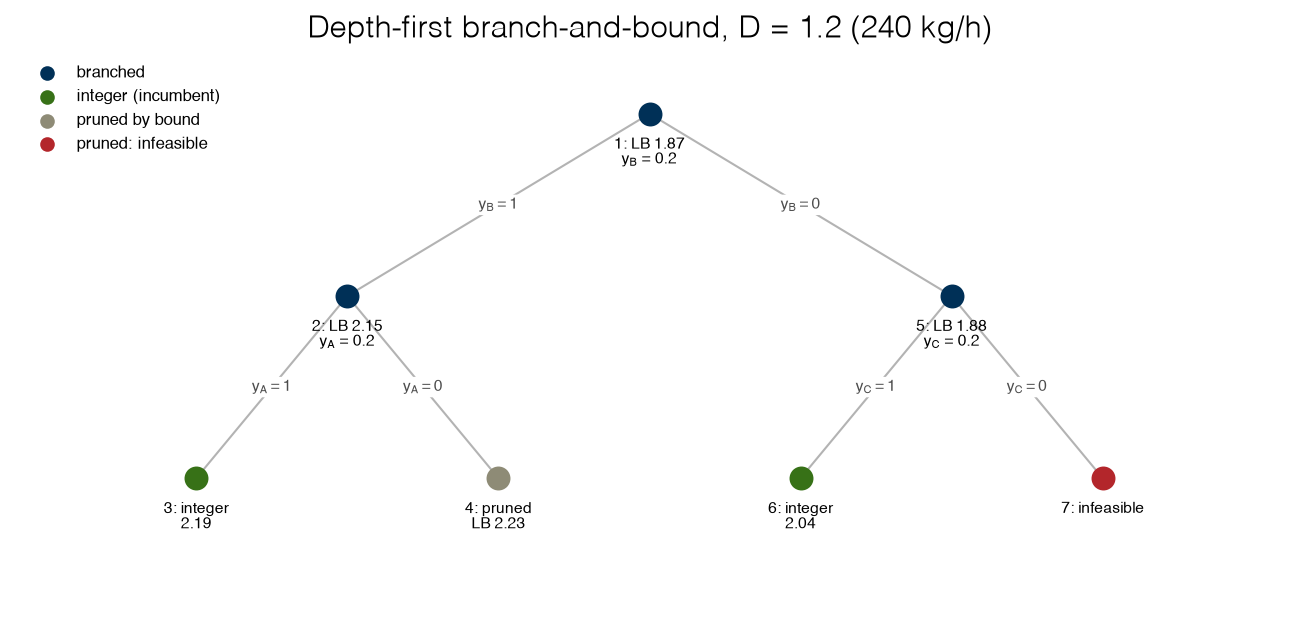

In [4]:
dfs = bt.fc_bb(F, e, D, order="dfs")
bt.print_tree_log(dfs)
print(f"\noptimum {dfs['best']:.2f} per-unit ({el.to_mw(dfs['best']):.2f} MW): {bt.config(dfs['z'], 3)} on, "
      f"loads {np.round(dfs['z'][:3], 2)}; {dfs['nodes']} nodes, {dfs['stats']}")

def node_label(r):
    if r['status'] == 'branch':
        return f"{r['id']}: LB {r['bound']:.2f}\n$y_{r['var']}$ = {r['z'][3 + el.NAMES.index(r['var'])]:.1f}"
    if r['status'] == 'integer':
        return f"{r['id']}: integer\n{r['bound']:.2f}"
    if r['status'] == 'bound':
        return f"{r['id']}: pruned\nLB {r['bound']:.2f}"
    return f"{r['id']}: infeasible"

fig, ax = plt.subplots(figsize=(9, 4.6))
bt.draw_tree(dfs['log'], ax, label=node_label)
ax.set_title('Depth-first branch-and-bound, D = 1.2 (240 kg/h)')
for s, lab in [('branch', 'branched'), ('integer', 'integer (incumbent)'), ('bound', 'pruned by bound'),
               ('infeasible', 'pruned: infeasible')]:
    ax.scatter([], [], color=bt.STATUS_COLOR[s], label=lab)
ax.legend(loc='upper left', fontsize=8, frameon=False);

We can read the tree node by node, and the numbers at each node can be checked by hand from the merit order.

1. **Root.** Bound 1.87, with $y_B = 0.2$ fractional. Branch on $y_B$.
2. **$y_B = 1$.** B now pays its full standby cost, so its marginal price is just $e_B = 1.45$, cheaper than A's relaxed 1.5. B fills to capacity and A takes the last 0.2 with $y_A = 0.2$. Bound $0.4 + 1.45 + 0.2 \times 1.5 = 2.15$. Branch on $y_A$.
3. **$y_A = 1$.** Integer: A and B both on, A at 0.2 and B at 1.0, cost 2.19. First incumbent.
4. **$y_A = 0$.** B carries 1.0 and C the last 0.2 with $y_C = 0.2$: bound 2.23, worse than the incumbent 2.19. Pruned by bound.
5. **$y_B = 0$.** A at full load and C at 0.2 with $y_C = 0.2$: bound 1.88. Still below the incumbent, so we branch on $y_C$.
6. **$y_C = 1$.** Integer: A and C, cost 2.04. A better incumbent.
7. **$y_C = 0$.** Only A is left, and it cannot make 1.2. Pruned by infeasibility.

When no nodes remain, we have proven that A+C at 2.04 (13.33 MW) is optimal, with stack A at full load and C at 0.2. In total we solved seven LPs (seven nodes processed, and here also seven nodes created). Complete enumeration would have needed eight LPs, so the saving is small in this case (the three-binary example in the lecture makes the same comparison, with five LPs against eight). However, the saving will grow quickly with the number of binaries, since a single prune by bound high in a large tree discards an exponential number of configurations at once.

**Rounding the relaxation fails.** It is tempting to skip the tree, solve the relaxation and round each $y_i$ to the nearest integer. In this case the root solution $y = (1, 0.2, 0)$ rounds to \"A on, B and C off\", which is not enough to meet the demand.

In [5]:
y_round = np.round(z[3:]).astype(int)
_, v = bt.fc_lp(F, e, D, [1.0] * 3, [(0, yi) for yi in y_round] + [(yi, yi) for yi in y_round])
print(f"root y = {np.round(z[3:], 2)} rounds to {y_round}: "
      + ("infeasible" if not np.isfinite(v) else f"cost {v:.2f}"))

root y = [1.  0.2 0. ] rounds to [1 0 0]: infeasible


If we round up instead and turn on both A and B, we get a feasible plan. However, this plan costs 2.19, which is 7% above the optimum, and is also the wrong configuration: B was preferred by the relaxation, while C is used in the optimal plan.

**Integrality does visible work.** Why did the relaxation prefer B for the last 0.2, when the optimum uses C? In the relaxation the standby cost of a stack is paid pro rata, so for 0.2 of load B costs $0.2 \times 0.4 + 0.2 \times 1.45 = 0.37$ and C costs $0.2 \times 0.2 + 0.2 \times 1.7 = 0.38$, and B wins by a narrow margin. Once each stack is required to be wholly on, C costs $0.2 + 0.34 = 0.54$ and B costs $0.4 + 0.29 = 0.69$, so C wins clearly by a margin of 0.15. The ranking of the stacks is changed by the binaries, which is why we cannot trust the relaxation alone to pick the configuration.

:::{exercise}
:label: ex-t25-tree

Run `bt.fc_bb` at $D = 1.5$ and $D = 1.8$, print the logs, and draw the trees. Which nodes are pruned for which reason? At either demand, does rounding the root relaxation give the optimal configuration?
:::

## Search order: depth-first and breadth-first

Branch-and-bound leaves several choices open, and the rules for making these choices are called heuristics in the lecture.

- **Which variable to branch on.** We branch on the most fractional binary. Alternatives include the variable whose branching most changes the objective.
- **Where to split.** For a binary there is only one way. For a general integer or a continuous variable, the split point is a choice (Topic 2.6).
- **Which node to explore next.** **Depth-first** search follows one branch down until it is pruned, which finds feasible solutions early and keeps few nodes in memory. **Breadth-first** search finishes each level of the tree before going deeper. **Best-first** search always explores the node with the lowest bound, which raises the global lower bound fastest.

No single rule is best on every problem, since the most effective choices will depend on the problem. For this reason production solvers allow the user to tune these rules or to supply new rules. Here is the same problem explored breadth-first:

node 1 [root]: bound 1.8700, y_B = 0.200 -> branch
    node 2 [y_B=0]: bound 1.8800, y_C = 0.200 -> branch
    node 3 [y_B=1]: bound 2.1500, y_A = 0.200 -> branch
        node 4 [y_C=0]: pruned: infeasible
        node 5 [y_C=1]: integer: new incumbent 2.0400
        node 6 [y_A=0]: pruned: bound 2.2300 >= 2.0400
        node 7 [y_A=1]: pruned: bound 2.1900 >= 2.0400

optimum 2.04 (A+C), 7 nodes, found at node 5, 2 prunes by bound


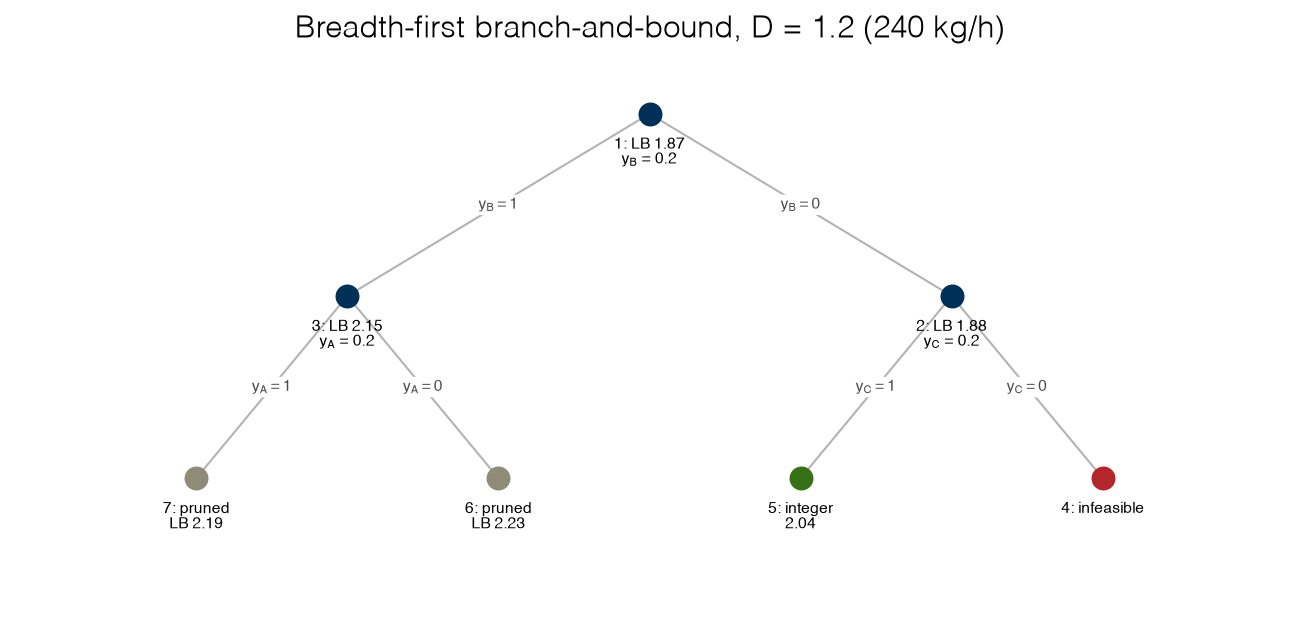

In [6]:
bfs = bt.fc_bb(F, e, D, order="bfs")
bt.print_tree_log(bfs)
first = next(r['id'] for r in bfs['log'] if r['status'] == 'integer' and abs(r['bound'] - bfs['best']) < 1e-9)
print(f"\noptimum {bfs['best']:.2f} ({bt.config(bfs['z'], 3)}), {bfs['nodes']} nodes, found at node {first}, "
      f"{bfs['stats']['bound']} prunes by bound")

fig, ax = plt.subplots(figsize=(9, 4.6))
bt.draw_tree(bfs['log'], ax, label=node_label)
ax.set_title('Breadth-first branch-and-bound, D = 1.2 (240 kg/h)');

With breadth-first search, the same seven nodes are processed in a different order. The optimum is found at the fifth node, and since A+B is never encountered as an incumbent, both nodes on the $y_B = 1$ side are pruned by bound against 2.04. The answer is the same as before, and this is true in general: **the branching variable and the node order change the speed of branch-and-bound, not its answer**, because every rule we could choose only discards nodes that provably cannot hold a better solution.

:::{exercise}
:label: ex-t25-node-order

Change `fc_bb` (a copy of it in your notebook) so that depth-first takes the $y = 0$ child first. How many nodes does it process at $D = 1.2$, and at which node does it find the optimum? Then write a best-first version that keeps the open nodes in a priority queue keyed by their parent's bound. Compare the three orders by the number of nodes processed.
:::

## A production solver

The same tree is used in real MILP solvers, along with many refinements. Below we write the same model in Pyomo and hand it to HiGHS with the log printed:

In [7]:
def fixed_charge_model(D):
    m = pyo.ConcreteModel()
    m.I = pyo.Set(initialize=el.NAMES)
    m.x = pyo.Var(m.I, bounds=(0, 1))
    m.y = pyo.Var(m.I, within=pyo.Binary)
    m.demand = pyo.Constraint(expr=sum(m.x[i] for i in m.I) == D)
    m.on_off = pyo.Constraint(m.I, rule=lambda m, i: m.x[i] <= m.y[i])
    m.cost = pyo.Objective(expr=sum(el.F_FIXED[i] * m.y[i] + el.E_LINEAR[i] * m.x[i] for i in m.I))
    return m

highs = pyo.SolverFactory('appsi_highs')
if highs.available(exception_flag=False):
    m = fixed_charge_model(D)
    res = highs.solve(m, tee=True)
    print(f"\nHiGHS: {'+'.join(i for i in el.NAMES if pyo.value(m.y[i]) > 0.5)} on, cost {pyo.value(m.cost):.2f}, "
          f"lower bound {res.problem.lower_bound:.2f}")
else:
    print("HiGHS is not available through Pyomo; the hand tree above is the reference solution.")


HiGHS: A+C on, cost 2.04, lower bound 2.04


The log reports the same quantities as our tree, although the exact layout will depend on the HiGHS version. The columns labeled *BestBound* and *BestSol* are the global lower bound and the incumbent, and *Gap* is the relative difference between the bound and the incumbent. In the run used to write this page, a primal heuristic found the plan A+B at 2.19 before the root relaxation was solved, which is the same first incumbent found by our depth-first tree at node 3. The root relaxation then gave the same bound as ours (1.87, a gap of about 15%), and the solver closed that gap at the root without the six further nodes needed by our tree. Your log may show a different heuristic or a different order of events, but the root bound of 1.87 and the final bounds (equal at 2.04) should not change.

Two kinds of refinement explain this difference. **Presolve** simplifies the model before and during the solve, for example by fixing binaries with values that can be deduced and then restarting on the smaller model (in our run it fixed one of the three binaries). **Cutting planes** are extra linear inequalities that are satisfied by every integer solution but not by the fractional relaxation point, so adding them tightens the relaxation without branching. The *Cuts* column of the log counts the cuts, and in our run a small sub-problem heuristic found the optimum at the same time. We will not develop cutting planes in this course. For now it is enough to know that cutting planes, together with presolve and heuristics, are the reason that the tree of a production solver is much smaller than a textbook tree, and that the mismatch with our hand tree is expected. The important thing is that both finish with the same certificate: lower and upper bounds that are equal at 2.04.

Why should we learn the algorithm if a solver can run it as a black box? There are two reasons. The first is that the idea of branch-and-bound is useful beyond MILPs. When a problem is too hard to solve exactly, it helps to look for easier problems that bound it from above and below. A pair of bounds is useful in itself, since knowing that a cost lies between two values is often enough to make a decision, and every model is approximate anyway. The second reason is that knowing what the solver does will help us to get the most out of the solver: it lets us recognize a weak formulation from a large root gap, choose node-selection and branching options, and give the solver a good starting incumbent or a problem-specific bound.

:::{exercise}
:label: ex-t25-solver

Build a larger fleet by repeating the three stacks ten times (30 stacks, with $F$ and $e$ perturbed slightly, for example by `np.random.default_rng(0).normal(0, 0.01, 30)`) and a demand of 12. Solve it with HiGHS and read the log: root bound, first incumbent, number of nodes, final gap. How many configurations would complete enumeration need?
:::

## Branching on continuous variables: a look ahead

We could trust every bound in this topic, since the relaxation at each node was an LP and all LPs are convex. The value returned by the solver at each node was the true minimum of the relaxation, so pruning by bound never discarded a better solution.

Note that branching itself does not need integers. A continuous variable with bounds $[l, u]$ can be split at any interior point $c$ into the children $[l, c]$ and $[c, u]$, and every solution survives in one of the two children. Topic 2.4 ended with the S-shaped power curve, which makes the relaxation at each node a non-convex NLP. In Topic 2.6 we will see how to recover valid bounds for this problem from convex underestimators of the curve, and how splitting the continuous loads makes those bounds tighter. The resulting **spatial branch-and-bound** is the same algorithm as in this topic, but with one more kind of branch.

:::{exercise}
:label: ex-t25-continuous

Take the convex ohmic dispatch of Topic 2.1 (each stack draws $x + r_i x^2$, with $r = (0.5, 0.35, 0.7)$, $D = 1.2$, no binaries). Solve it once with all loads in $[0, 1]$. Then split stack A's load interval at its optimal value and solve each child. Do the children's bounds ever improve on the root's, and why is branching useless on a convex problem?
:::

## Summary

- Branch-and-bound is the bound-pair applied recursively. A relaxation (for a MILP, the LP relaxation) gives a lower bound; any feasible point gives an upper bound, the incumbent.
- At each node: relax, then prune by infeasibility, by integrality, or by bound; otherwise branch on a fractional binary. When no nodes remain, the incumbent is certified optimal.
- On the electrolyzer plant at 240 kg/h the root bound is 1.87 (12.22 MW); depth-first search processes 7 nodes and certifies A+C at 2.04 (13.33 MW). Breadth-first search processes the same 7 nodes and finds the optimum fifth.
- Rounding the relaxation fails (it is infeasible here), and integrality changes the ranking of the stacks, so the relaxation alone cannot choose the configuration.
- Node order and the choice of branching variable change the speed, not the answer.
- Production solvers add presolve, heuristics and cutting planes, so their trees are smaller; they report the same bound-pair as a gap.

## Additional Reading

- Land, A. H., and Doig, A. G. An automatic method of solving discrete programming problems. *Econometrica* 28, 497–520 (1960). The original branch-and-bound paper.
- Wolsey, L. A. *Integer Programming*, 2nd ed. Wiley, 2020. Relaxations, branch-and-bound and cutting planes, at the next level of depth.
- Bertsimas, D., and Tsitsiklis, J. N. *Introduction to Linear Optimization*. Athena Scientific, 1997. Chapters 10–11 on integer programming.
- Ravindran, A., Ragsdell, K. M., and Reklaitis, G. V. *Engineering Optimization: Methods and Applications*, 2nd ed. Wiley, 2006. Integer programming and branch-and-bound for engineers.
- Achterberg, T. SCIP: solving constraint integer programs. *Mathematical Programming Computation* 1, 1–41 (2009). How a modern solver combines branching, presolve, cutting planes and heuristics.